In [1]:
import pandas as pd
import numpy as np
from sklearn.preprocessing import StandardScaler

In [2]:
url = "https://archive.ics.uci.edu/ml/machine-learning-databases/00292/Wholesale%20customers%20data.csv"

In [3]:
df = pd.read_csv(url)

In [4]:
df.head()


,Channel,Region,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicassen
0,2,3,12669,9656,7561,214,2674,1338
1,2,3,7057,9810,9568,1762,3293,1776
2,2,3,6353,8808,7684,2405,3516,7844
3,1,3,13265,1196,4221,6404,507,1788
4,2,3,22615,5410,7198,3915,1777,5185


In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 440 entries, 0 to 439
Data columns (total 8 columns):
 #   Column            Non-Null Count  Dtype
---  ------            --------------  -----
 0   Channel           440 non-null    int64
 1   Region            440 non-null    int64
 2   Fresh             440 non-null    int64
 3   Milk              440 non-null    int64
 4   Grocery           440 non-null    int64
 5   Frozen            440 non-null    int64
 6   Detergents_Paper  440 non-null    int64
 7   Delicassen        440 non-null    int64
dtypes: int64(8)
memory usage: 27.6 KB


In [6]:
df.shape

(440, 8)

In [7]:
df.isnull().sum()

,0
Channel,0
Region,0
Fresh,0
Milk,0
Grocery,0
Frozen,0
Detergents_Paper,0
Delicassen,0


In [8]:
df = df.drop_duplicates()

In [9]:
features = ["Fresh", "Milk", "Grocery", "Frozen","Detergents_Paper","Delicassen"]

In [10]:
X = df[features].copy()

In [11]:
X = X.fillna(X.median())


In [12]:
(X < 0).sum()


,0
Fresh,0
Milk,0
Grocery,0
Frozen,0
Detergents_Paper,0
Delicassen,0


In [13]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

In [14]:
X_scaled_df = pd.DataFrame(X_scaled,columns=features,index=X.index)

In [15]:
X_scaled_df.head()

,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicassen
0,0.052933,0.523568,-0.041115,-0.589367,-0.043569,-0.066339
1,-0.391302,0.544458,0.170318,-0.270136,0.086407,0.089151
2,-0.447029,0.408538,-0.028157,-0.137536,0.133232,2.243293
3,0.100111,-0.624020,-0.392977,0.687144,-0.498588,0.093411
4,0.840239,-0.052396,-0.079356,0.173859,-0.231918,1.299347


In [16]:
X_scaled_df.shape

(440, 6)

In [17]:
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, davies_bouldin_score


In [18]:
wcss = []

In [19]:
for k in range(1, 11):
    model = KMeans(n_clusters=k, random_state=42, n_init=10)
    model.fit(X_scaled)
    wcss.append(model.inertia_)

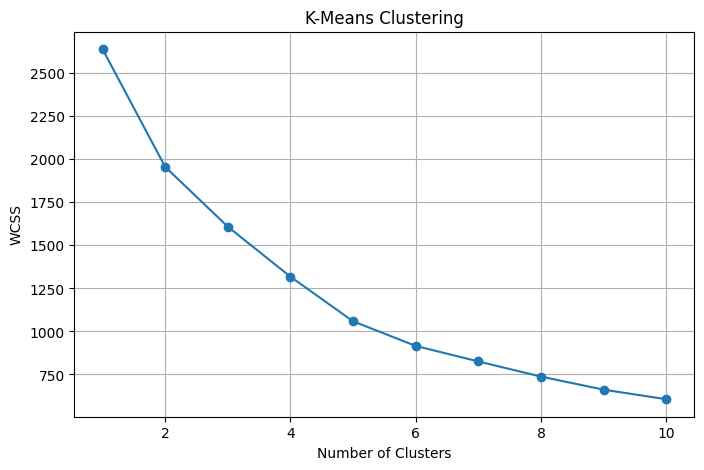

In [61]:
plt.figure(figsize=(8, 5))
plt.plot(range(1, 11), wcss, marker='o')
plt.title("K-Means Clustering")
plt.xlabel("Number of Clusters")
plt.ylabel("WCSS")
plt.grid(True)
plt.show()

In [21]:
kmeans = KMeans(n_clusters=3, random_state=42, n_init=10)
df["KMeans_Cluster"] = kmeans.fit_predict(X_scaled)

In [23]:
print(df["KMeans_Cluster"].value_counts().sort_index())

KMeans_Cluster
0     45
1    393
2      2
Name: count, dtype: int64


In [25]:
X_log = np.log1p(X)

In [26]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_log)


In [27]:
print("Shape:", X_scaled.shape)


Shape: (440, 6)


In [28]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, davies_bouldin_score


In [29]:
kmeans = KMeans(n_clusters=3, random_state=42, n_init=10)
df["KMeans_Cluster"] = kmeans.fit_predict(X_scaled)

In [30]:
print("Customers in each cluster:")
print(df["KMeans_Cluster"].value_counts().sort_index())

Customers in each cluster:
KMeans_Cluster
0     80
1    147
2    213
Name: count, dtype: int64


In [31]:
print("\nSilhouette Score:",round(silhouette_score(X_scaled, df["KMeans_Cluster"]), 4))

print("Davies-Bouldin Index:", round(davies_bouldin_score(X_scaled, df["KMeans_Cluster"]), 4))


Silhouette Score: 0.2594
Davies-Bouldin Index: 1.3406


In [32]:
from sklearn.decomposition import PCA

In [33]:
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)

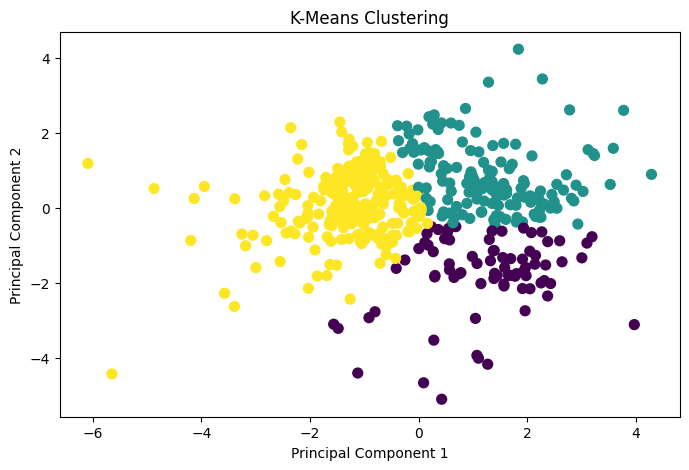

In [44]:
plt.figure(figsize=(8, 5))
plt.scatter(
    X_pca[:, 0],
    X_pca[:, 1],
    c=df["KMeans_Cluster"],
    cmap="viridis",
    s=50
)
plt.title("K-Means Clustering")
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.show()

In [38]:
from sklearn.cluster import AgglomerativeClustering
hierarchical = AgglomerativeClustering(n_clusters=3,linkage="ward"
)

In [39]:
df["Hierarchical_Cluster"] = hierarchical.fit_predict(X_scaled)

In [40]:
print("Hierarchical Cluster Counts:")
print(df["Hierarchical_Cluster"].value_counts().sort_index())


Hierarchical Cluster Counts:
Hierarchical_Cluster
0    262
1     53
2    125
Name: count, dtype: int64


In [41]:
silhouette_h = silhouette_score(
    X_scaled, df["Hierarchical_Cluster"]
)

dbi_h = davies_bouldin_score(
    X_scaled, df["Hierarchical_Cluster"]
)

print("\nHierarchical Clustering Evaluation")
print("Silhouette Score:", round(silhouette_h, 4))
print("Davies-Bouldin Index:", round(dbi_h, 4))


Hierarchical Clustering Evaluation
Silhouette Score: 0.2547
Davies-Bouldin Index: 1.539


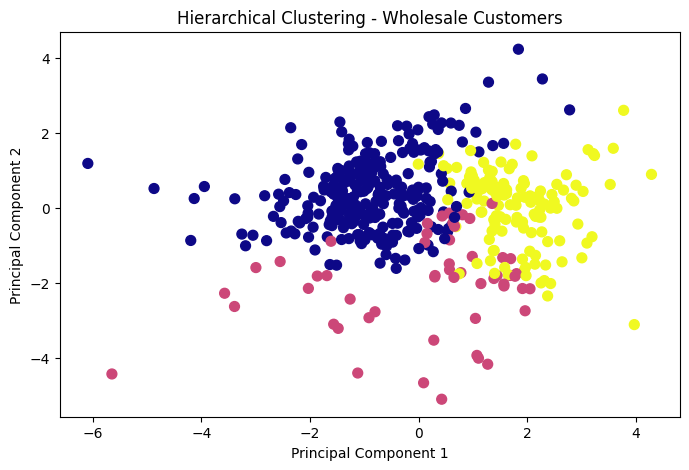

In [42]:
plt.figure(figsize=(8, 5))

plt.scatter(
    X_pca[:, 0],
    X_pca[:, 1],
    c=df["Hierarchical_Cluster"],
    cmap="plasma",
    s=50
)

plt.title("Hierarchical Clustering")
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.show()

In [45]:
from sklearn.cluster import DBSCAN

In [46]:
dbscan = DBSCAN(eps=0.8, min_samples=5)
dbscan_labels = dbscan.fit_predict(X_scaled)

In [47]:
df["DBSCAN_Cluster"] = dbscan_labels

print("DBSCAN Cluster Distribution:")
print(df["DBSCAN_Cluster"].value_counts().sort_index())

DBSCAN Cluster Distribution:
DBSCAN_Cluster
-1    230
 0    200
 1      5
 2      5
Name: count, dtype: int64


In [48]:
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)

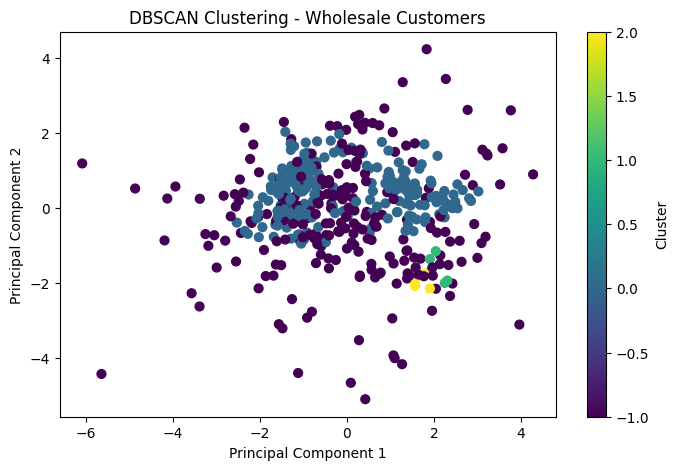

In [50]:
plt.figure(figsize=(8, 5))
plt.scatter(
    X_pca[:, 0],
    X_pca[:, 1],
    c=dbscan_labels,
    cmap="viridis",
    s=40
)

plt.title("DBSCAN Clustering - Wholesale Customers")
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.colorbar(label="Cluster")
plt.show()


In [51]:
non_noise = dbscan_labels != -1
filtered_labels = dbscan_labels[non_noise]
filtered_data = X_scaled[non_noise]


In [52]:
n_clusters = len(set(filtered_labels))

if 2 <= n_clusters < len(filtered_labels):
    silhouette = silhouette_score(filtered_data, filtered_labels)
    db_index = davies_bouldin_score(filtered_data, filtered_labels)

    print("DBSCAN Silhouette Score:", round(silhouette, 4))
    print("DBSCAN Davies-Bouldin Index:", round(db_index, 4))
else:
    print("DBSCAN did not produce enough non-noise clusters for evaluation.")

DBSCAN Silhouette Score: 0.2885
DBSCAN Davies-Bouldin Index: 0.7117


In [54]:
def divisive_clustering(X, n_clusters=3):
    clusters = [np.arange(len(X))]

    while len(clusters) < n_clusters:
        splittable = [
            i for i, indices in enumerate(clusters)
            if len(indices) >= 2
        ]

        if not splittable:
            break

        largest_index = max(
            splittable,
            key=lambda i: len(clusters[i])
        )

        indices = clusters.pop(largest_index)

        km = KMeans(
            n_clusters=2,
            random_state=42,
            n_init=10
        )

        labels = km.fit_predict(X[indices])

        clusters.append(indices[labels == 0])
        clusters.append(indices[labels == 1])

    final_labels = np.zeros(len(X), dtype=int)

    for cluster_id, indices in enumerate(clusters):
        final_labels[indices] = cluster_id

    return final_labels

In [56]:
divisive_labels = divisive_clustering(X_scaled, n_clusters=3)

df["Divisive_Cluster"] = divisive_labels

print("Divisive Cluster Distribution:")
print(df["Divisive_Cluster"].value_counts().sort_index())

Divisive Cluster Distribution:
Divisive_Cluster
0    188
1    153
2     99
Name: count, dtype: int64


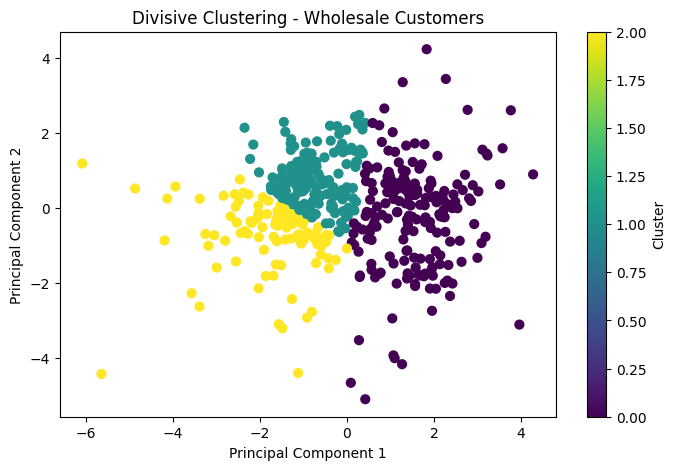

In [57]:
plt.figure(figsize=(8, 5))

plt.scatter(
    X_pca[:, 0],
    X_pca[:, 1],
    c=divisive_labels,
    cmap="viridis",
    s=40
)

plt.title("Divisive Clustering - Wholesale Customers")
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.colorbar(label="Cluster")
plt.show()

In [58]:
import pandas as pd
from sklearn.metrics import silhouette_score, davies_bouldin_score

results = []

algorithms = {
    "K-Means": df["KMeans_Cluster"].to_numpy(),
    "Agglomerative Clustering": df["Hierarchical_Cluster"].to_numpy(),
    "Divisive Clustering": df["Divisive_Cluster"].to_numpy(),
    "DBSCAN": df["DBSCAN_Cluster"].to_numpy()
}

for name, labels in algorithms.items():

    if name == "DBSCAN":
        mask = labels != -1
        X_eval = X_scaled[mask]
        labels_eval = labels[mask]
    else:
        X_eval = X_scaled
        labels_eval = labels

    n_clusters = len(set(labels_eval))

    if 2 <= n_clusters < len(labels_eval):
        silhouette = silhouette_score(X_eval, labels_eval)
        db_index = davies_bouldin_score(X_eval, labels_eval)
    else:
        silhouette = None
        db_index = None

    results.append({
        "Algorithm": name,
        "Silhouette Score": silhouette,
        "Davies-Bouldin Index": db_index
    })

comparison = pd.DataFrame(results)

print("Clustering Algorithm Comparison:")
print(comparison.round(4).to_string(index=False))

Clustering Algorithm Comparison:
               Algorithm  Silhouette Score  Davies-Bouldin Index
                 K-Means            0.2594                1.3406
Agglomerative Clustering            0.2547                1.5390
     Divisive Clustering            0.1891                1.5936
                  DBSCAN            0.2885                0.7117
